
# CS5344 — Exploratory Data Analysis
## Tabular Data Augmentation for Anomaly Detection (NSL-KDD & UNSW-NB15)

**Objective of this notebook.** Before designing a synthetic-data generator, we need a
rigorous, evidence-based picture of both released training sets. This EDA is scoped
specifically to the constraints of the competition, not generic profiling:

- The **submission is normal-only** (`is_anomaly == 0` rows), so everything we learn about
  the *normal* class — its outliers, its correlation structure, its logical constraints —
  matters more than characterizing the attack class.
- Downstream scoring trains two **fixed, non-negotiable detectors** (ECOD, IsolationForest)
  on our synthetic data and reports **AUPRC** against hidden validation/test rows that
  include **anomaly types never seen in training**. This means the generator must extrapolate
  a *believable normal manifold*, not just memorize/perturb the training rows (the starter
  kit's bootstrap-and-jitter baseline does the latter).
- We must ship **one transferable pipeline for both datasets** (params may differ), so the
  EDA below is implemented as a **shared function library applied identically to both
  datasets** — this both keeps the two analyses comparable and forces the augmentation
  method design to generalize rather than special-case one schema.

**Coverage.** The brief's six required lenses (schema, missingness, univariate, outliers,
correlation, domain constraints) are each implemented below, plus additional steps that this
problem specifically calls for:

1. **Duplicate-row audit** — KDD-family datasets are notorious for duplicated connections;
   duplicates silently bias a generator toward over-represented rows.
2. **Constant / near-constant feature audit** — zero-variance columns carry no signal and
   should not be modelled or scored for fidelity.
3. **High-cardinality categorical audit** — `service`/`proto` have 67–86 levels; a generator
   that treats every level as equally likely to recombine with other features will produce
   implausible synthetic rows.
4. **Cross-column logical relations** (not just per-column ranges) — e.g. "no root shell
   without login", "TCP-only fields must be zero for non-TCP protocols" — these become hard
   **post-processing rejection rules** for the generator's output.
5. **Point-biserial correlation with the label** — a cheap proxy for which normal-side
   feature interactions a generator most needs to preserve to stay useful for detection.
6. **PCA projection (normal vs. abnormal)** — a sanity check on how separable/entangled the
   two classes already are in linear feature space.
7. **Exported artifacts** — an IsolationForest-scrubbed normal training set and a
   machine-readable constraint spec (JSON) per dataset, so the augmentation notebook can
   consume this EDA's conclusions directly instead of re-deriving them.


In [1]:

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 9, "axes.labelsize": 8,
                      "xtick.labelsize": 7, "ytick.labelsize": 7})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

LABEL_COL = "is_anomaly"
OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DATASETS = {
    "NSL-KDD": {"path": "train_nslkdd.csv", "slug": "nslkdd"},
    "UNSW-NB15": {"path": "train_unsw.csv", "slug": "unsw"},
}



## 0. Shared EDA function library

Every section below (schema, missingness, univariate, outliers, correlation, constraints)
is written **once** here and invoked once per dataset. This is deliberate: the project
requires "one transferable pipeline for both datasets", and writing the analysis as reusable
functions is the cheapest way to guarantee the two EDAs are actually comparable (same
definitions of "outlier", "skewed", "correlated") rather than two hand-rolled analyses that
drift apart.


In [2]:

def split_feature_types(df, label_col=LABEL_COL):
    '''Continuous vs. binary vs. categorical split, mirroring the starter kit's logic.'''
    feature_cols = [c for c in df.columns if c != label_col]
    categorical_cols = [
        c for c in feature_cols
        if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c])
    ]
    numeric_cols = [c for c in feature_cols if c not in categorical_cols]
    binary_cols = [
        c for c in numeric_cols
        if df[c].dropna().nunique() <= 2 and set(df[c].dropna().unique()).issubset({0, 1})
    ]
    continuous_cols = [c for c in numeric_cols if c not in binary_cols]
    return {
        "feature_cols": feature_cols,
        "categorical_cols": categorical_cols,
        "numeric_cols": numeric_cols,
        "binary_cols": binary_cols,
        "continuous_cols": continuous_cols,
    }


def schema_report(df, name, label_col=LABEL_COL):
    print("=" * 88)
    print(f"SCHEMA VERIFICATION — {name}")
    print("=" * 88)
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
    df.info()

    types = split_feature_types(df, label_col)
    print(f"\nContinuous numeric  : {len(types['continuous_cols'])}")
    print(f"Binary (0/1) numeric: {len(types['binary_cols'])} -> {types['binary_cols']}")
    print(f"Categorical (string): {len(types['categorical_cols'])} -> {types['categorical_cols']}")

    n_dup = int(df.duplicated().sum())
    print(f"\nExact duplicate rows: {n_dup} ({n_dup / len(df):.3%})")

    const_cols = [c for c in types["numeric_cols"] if df[c].nunique() == 1]
    near_const_cols = [c for c in types["numeric_cols"] if df[c].nunique() == 2 and c not in types["binary_cols"]]
    print(f"Constant columns (zero variance): {const_cols}")
    print(f"Near-constant columns (2 distinct non-{{0,1}} values): {near_const_cols}")

    label_dist = df[label_col].value_counts(normalize=True).rename({0: "normal (0)", 1: "abnormal (1)"})
    print(f"\nLabel balance:\n{label_dist.round(4)}")

    display(df.nunique().sort_values().to_frame("n_unique"))
    return types


def missingness_report(df, name):
    print("=" * 88)
    print(f"MISSINGNESS — {name}")
    print("=" * 88)

    null_counts = df.isna().sum()
    report = pd.DataFrame({"n_missing": null_counts, "pct_missing": (null_counts / len(df) * 100).round(3)})
    report = report[report.n_missing > 0].sort_values("pct_missing", ascending=False)
    if report.empty:
        print("No NaN values detected in any column (curated benchmark dataset).")
    else:
        display(report)

    # Sentinel / placeholder tokens masquerading as valid strings (e.g. '-', '?').
    types = split_feature_types(df)
    sentinel_tokens = {"-", "?", "", "none", "None", "NA", "N/A"}
    for c in types["categorical_cols"]:
        hits = df[c].isin(sentinel_tokens)
        if hits.any():
            print(f"  Sentinel token in '{c}': {df.loc[hits, c].value_counts().to_dict()} "
                  f"covering {hits.mean():.2%} of rows — per the data dictionary this is a valid "
                  f"category (e.g. 'no well-known service'), NOT missingness, so it must not be imputed.")

    fig, ax = plt.subplots(figsize=(10, 3.5))
    msno.matrix(df.sample(min(2000, len(df)), random_state=RANDOM_SEED), ax=ax, sparkline=False)
    ax.set_title(f"Missingness matrix (2,000-row sample) — {name}")
    plt.tight_layout()
    plt.show()


def univariate_numeric(df, numeric_cols, name, ncols=6):
    print("=" * 88)
    print(f"UNIVARIATE PROFILING — numeric — {name}")
    print("=" * 88)

    rows = []
    for c in numeric_cols:
        s = df[c].astype(float)
        skew = s.skew()
        if abs(skew) > 2:
            suggestion = "log1p (heavy right-skew)"
        elif abs(skew) > 0.75:
            suggestion = "quantile / Yeo-Johnson (moderate skew)"
        else:
            suggestion = "none needed"
        rows.append({
            "feature": c, "skew": round(skew, 2), "kurtosis": round(s.kurt(), 2),
            "pct_zero": round((s == 0).mean() * 100, 1),
            "min": s.min(), "max": s.max(),
            "transform_suggestion": suggestion,
        })
    stats_df = pd.DataFrame(rows).sort_values("skew", key=lambda x: x.abs(), ascending=False)
    display(stats_df)
    n_heavy = (stats_df["transform_suggestion"] == "log1p (heavy right-skew)").sum()
    print(f"{n_heavy}/{len(stats_df)} continuous features are heavily right-skewed and should be "
          f"log1p-transformed before fitting a generator, then inverse-transformed (expm1) on output.")

    n = len(numeric_cols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.4, nrows * 1.9))
    axes = np.array(axes).reshape(-1)
    for i, c in enumerate(numeric_cols):
        sns.histplot(df[c], kde=True, ax=axes[i], bins=30, color="#4C72B0")
        axes[i].set_title(c, fontsize=7)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    fig.suptitle(f"Univariate distributions — {name}", y=1.005)
    plt.tight_layout()
    plt.show()
    return stats_df


def univariate_categorical(df, categorical_cols, name, top_k=15):
    print("=" * 88)
    print(f"UNIVARIATE PROFILING — categorical — {name}")
    print("=" * 88)

    card = df[categorical_cols].nunique().to_frame("n_categories")
    display(card)
    for c in categorical_cols:
        if df[c].nunique() > 20:
            top5_share = df[c].value_counts(normalize=True).head(5).sum()
            print(f"  '{c}' is high-cardinality ({df[c].nunique()} levels); top-5 levels cover "
                  f"{top5_share:.1%} of rows — recommend bucketing the long tail into an 'other' "
                  f"category before generative modelling to avoid inventing implausible rare levels.")

    fig, axes = plt.subplots(1, len(categorical_cols), figsize=(6 * len(categorical_cols), 3.6))
    if len(categorical_cols) == 1:
        axes = [axes]
    for ax, c in zip(axes, categorical_cols):
        vc = df[c].value_counts().head(top_k)
        ax.barh(vc.index[::-1], vc.values[::-1], color="#55A868")
        ax.set_title(f"{c} (top {min(top_k, df[c].nunique())} of {df[c].nunique()})")
        ax.set_xlabel("count")
    plt.tight_layout()
    plt.show()


def outlier_report(df, continuous_cols, name, label_col=LABEL_COL, contamination=0.02, ncols=6):
    print("=" * 88)
    print(f"OUTLIER DETECTION — {name}")
    print("=" * 88)

    nrows = int(np.ceil(len(continuous_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.3, nrows * 2.1))
    axes = np.array(axes).reshape(-1)
    for i, c in enumerate(continuous_cols):
        sns.boxplot(y=df[c], ax=axes[i], color="#C44E52", fliersize=1.2, linewidth=0.7)
        axes[i].set_title(c, fontsize=7)
        axes[i].set_ylabel("")
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    fig.suptitle(f"Boxplots — {name}", y=1.005)
    plt.tight_layout()
    plt.show()

    rows = []
    for c in continuous_cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        pct = ((df[c] < lo) | (df[c] > hi)).mean() * 100
        rows.append({"feature": c, "iqr_outlier_pct": round(pct, 2)})
    iqr_df = pd.DataFrame(rows).sort_values("iqr_outlier_pct", ascending=False)
    display(iqr_df.head(15))

    # Isolation Forest on the NORMAL-only subset: flags within-class outliers /
    # likely-mislabeled rows that a generator should not be trained on.
    normal_df = df[df[label_col] == 0].copy()
    X = normal_df[continuous_cols].fillna(0).to_numpy()
    Xs = StandardScaler().fit_transform(X)
    iso = IsolationForest(n_estimators=300, contamination=contamination,
                           random_state=RANDOM_SEED, n_jobs=-1)
    pred = iso.fit_predict(Xs)
    normal_df["_iso_outlier"] = pred == -1
    n_flagged = int(normal_df["_iso_outlier"].sum())
    print(f"\nIsolationForest (contamination={contamination}) flagged {n_flagged:,} / "
          f"{len(normal_df):,} normal rows ({n_flagged / len(normal_df):.2%}) as within-class outliers.")

    n_before_dedupe = len(normal_df)
    scrubbed = (
        normal_df.loc[~normal_df["_iso_outlier"], normal_df.columns.drop("_iso_outlier")]
        .drop_duplicates()
        .reset_index(drop=True)
    )
    n_dropped_dupes = n_before_dedupe - n_flagged - len(scrubbed)
    print(f"After also dropping exact duplicates: {len(scrubbed):,} rows kept "
          f"({n_dropped_dupes:,} additional duplicate rows removed).")

    fig, ax = plt.subplots(figsize=(5, 3.2))
    sns.histplot(iso.decision_function(Xs), bins=50, ax=ax, color="#8172B2")
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"IsolationForest decision function — normal rows, {name}")
    ax.set_xlabel("decision score (< 0 → flagged outlier)")
    plt.tight_layout()
    plt.show()

    return {"iqr_table": iqr_df, "scrubbed_normal": scrubbed}


def cramers_v(x, y):
    '''Bias-corrected Cramer's V (Bergsma 2013) for two categorical series.'''
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.sum().sum()
    phi2 = chi2 / n
    r, k = ct.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = max(1e-9, min(kcorr - 1, rcorr - 1))
    return float(np.sqrt(phi2corr / denom))


def correlation_report(df, numeric_cols, categorical_cols, name, label_col=LABEL_COL, corr_threshold=0.9):
    print("=" * 88)
    print(f"FEATURE CORRELATION — {name}")
    print("=" * 88)

    corr = df[numeric_cols].corr(method="pearson")
    side = min(0.32 * len(numeric_cols) + 3, 18)
    fig, ax = plt.subplots(figsize=(side, side))
    sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.6},
                xticklabels=True, yticklabels=True)
    ax.set_title(f"Pearson correlation — numeric features, {name}")
    plt.tight_layout()
    plt.show()

    cols = corr.columns.tolist()
    pairs = [
        {"feature_1": cols[i], "feature_2": cols[j], "pearson_r": round(corr.iloc[i, j], 3)}
        for i in range(len(cols)) for j in range(i + 1, len(cols))
        if abs(corr.iloc[i, j]) >= corr_threshold
    ]
    pairs_df = pd.DataFrame(pairs).sort_values("pearson_r", key=lambda x: x.abs(), ascending=False) if pairs else pd.DataFrame(columns=["feature_1", "feature_2", "pearson_r"])
    print(f"\nHighly correlated / redundant pairs (|r| >= {corr_threshold}): {len(pairs_df)}")
    if not pairs_df.empty:
        display(pairs_df)

    if len(categorical_cols) > 1:
        cv = pd.DataFrame(index=categorical_cols, columns=categorical_cols, dtype=float)
        for a in categorical_cols:
            for b in categorical_cols:
                cv.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])
        fig, ax = plt.subplots(figsize=(3.6, 3.0))
        sns.heatmap(cv.astype(float), cmap="viridis", vmin=0, vmax=1, annot=True, fmt=".2f", ax=ax)
        ax.set_title(f"Cramér's V — categorical features, {name}")
        plt.tight_layout()
        plt.show()

    label_corr = df[numeric_cols].apply(lambda s: s.corr(df[label_col])).dropna().sort_values(key=lambda x: x.abs(), ascending=False)
    top = label_corr.head(20)
    colors = ["#C44E52" if v < 0 else "#4C72B0" for v in top.values]
    fig, ax = plt.subplots(figsize=(5.5, 6))
    ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Top 20 |correlation| with {label_col} — {name}")
    plt.tight_layout()
    plt.show()

    return {"numeric_corr": corr, "high_corr_pairs": pairs_df, "label_corr": label_corr}


def pca_scatter(df, numeric_cols, name, label_col=LABEL_COL, sample_n=8000):
    d = df.sample(min(sample_n, len(df)), random_state=RANDOM_SEED)
    X = StandardScaler().fit_transform(d[numeric_cols].fillna(0))
    pcs = PCA(n_components=2, random_state=RANDOM_SEED).fit_transform(X)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    for lbl, color, lab in [(0, "#4C72B0", "normal"), (1, "#C44E52", "abnormal")]:
        m = d[label_col].values == lbl
        ax.scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.35, color=color, label=lab)
    ax.set_title(f"PCA (2D) of standardized numeric features — {name}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(markerscale=3)
    plt.tight_layout()
    plt.show()


def run_constraint_rules(df, rules, name):
    print("=" * 88)
    print(f"DOMAIN CONSTRAINTS — {name}")
    print("=" * 88)
    results, rule_spec = [], {}
    for rule in rules:
        valid_mask = rule["check"](df)
        n_violations = int((~valid_mask).sum())
        results.append({
            "rule": rule["name"], "description": rule["description"],
            "n_violations": n_violations, "pct_violations": round(n_violations / len(df) * 100, 4),
        })
        if rule.get("spec") is not None:
            rule_spec[rule["name"]] = rule["spec"]
    report = pd.DataFrame(results)
    display(report)
    return report, rule_spec


def save_constraints(rule_spec, slug):
    path = OUTPUT_DIR / f"{slug}_constraints.json"
    with open(path, "w") as f:
        json.dump(rule_spec, f, indent=2)
    print(f"Saved post-processing constraint spec -> {path}")



## 1. Dataset A — NSL-KDD

Refined KDD Cup 1999 network-intrusion data; one row = one network connection; 38 numeric +
3 categorical (`protocol_type`, `service`, `flag`) features; label `is_anomaly`.


### 1.1 Schema Verification

In [3]:

nslkdd = pd.read_csv(DATASETS["NSL-KDD"]["path"])
nslkdd_types = schema_report(nslkdd, "NSL-KDD")


SCHEMA VERIFICATION — NSL-KDD
Shape: 30,000 rows x 42 columns

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     30000 non-null  int64  
 1   src_bytes                    30000 non-null  int64  
 2   dst_bytes                    30000 non-null  int64  
 3   land                         30000 non-null  int64  
 4   wrong_fragment               30000 non-null  int64  
 5   urgent                       30000 non-null  int64  
 6   hot                          30000 non-null  int64  
 7   num_failed_logins            30000 non-null  int64  
 8   logged_in                    30000 non-null  int64  
 9   num_compromised              30000 non-null  int64  
 10  root_shell                   30000 non-null  int64  
 11  su_attempted                 30000 non-null  int64  
 12  num_root              

,n_unique
is_host_login,1
num_outbound_cmds,1
is_anomaly,2
num_shells,2
root_shell,2
logged_in,2
is_guest_login,2
urgent,2
land,2
protocol_type,3


### 1.2 Missingness

MISSINGNESS — NSL-KDD
No NaN values detected in any column (curated benchmark dataset).


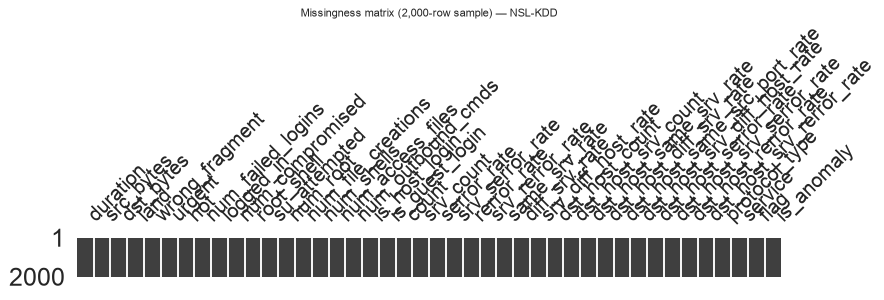

In [4]:
missingness_report(nslkdd, "NSL-KDD")

### 1.3 Univariate Profiling

UNIVARIATE PROFILING — numeric — NSL-KDD


,feature,skew,kurtosis,pct_zero,min,max,transform_suggestion
1,src_bytes,157.34,25807.84,29.9,0.0,1.379964e+09,log1p (heavy right-skew)
2,dst_bytes,155.80,25308.72,43.5,0.0,1.309937e+09,log1p (heavy right-skew)
6,num_compromised,61.89,4502.34,99.1,0.0,1.043000e+03,log1p (heavy right-skew)
8,num_root,58.28,3884.89,99.4,0.0,1.045000e+03,log1p (heavy right-skew)
5,num_failed_logins,50.51,2968.35,99.9,0.0,4.000000e+00,log1p (heavy right-skew)
10,num_access_files,41.76,2409.34,99.6,0.0,8.000000e+00,log1p (heavy right-skew)
9,num_file_creations,41.69,1984.77,99.7,0.0,4.000000e+01,log1p (heavy right-skew)
7,su_attempted,36.82,1378.38,99.9,0.0,2.000000e+00,log1p (heavy right-skew)
4,hot,14.20,211.38,98.2,0.0,3.300000e+01,log1p (heavy right-skew)
3,wrong_fragment,13.90,193.65,99.4,0.0,3.000000e+00,log1p (heavy right-skew)


21/30 continuous features are heavily right-skewed and should be log1p-transformed before fitting a generator, then inverse-transformed (expm1) on output.


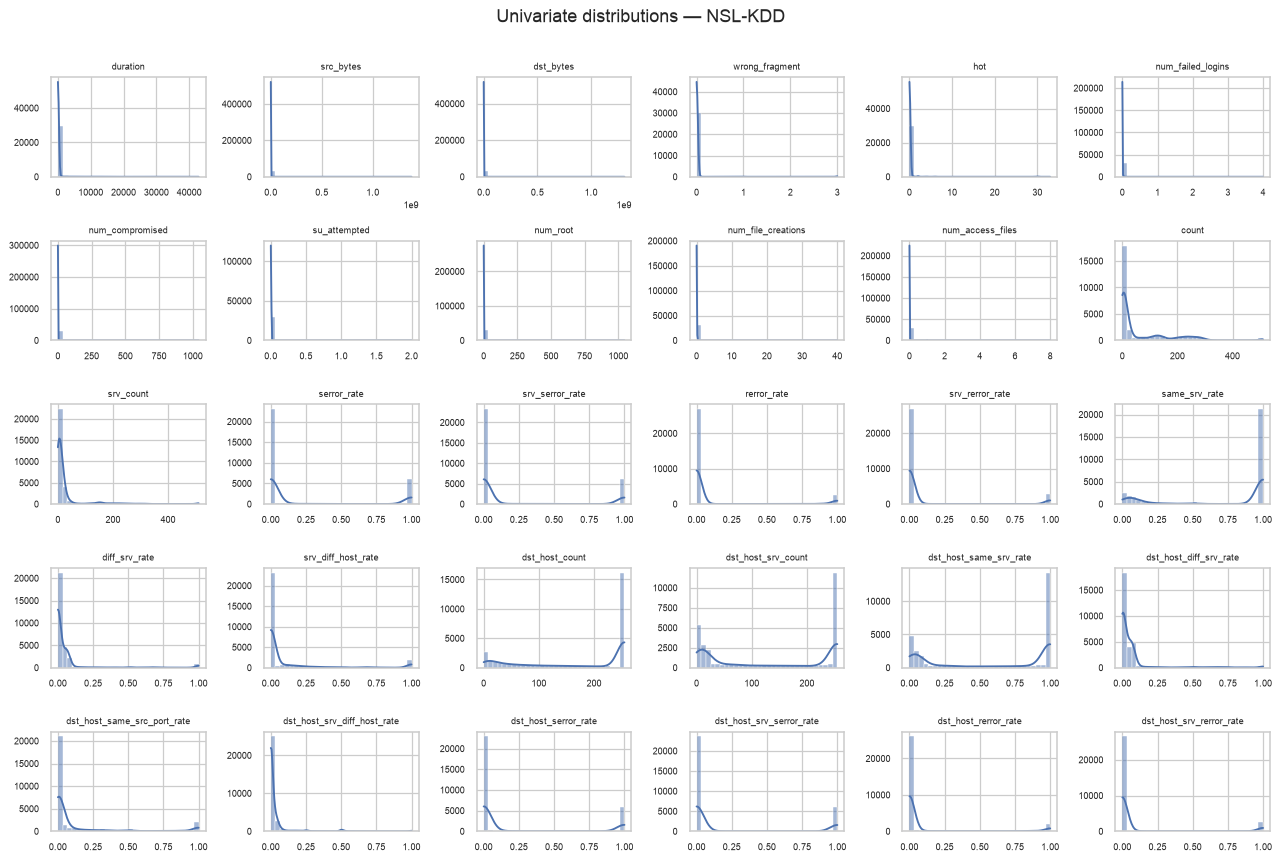

In [5]:
nslkdd_num_stats = univariate_numeric(nslkdd, nslkdd_types["continuous_cols"], "NSL-KDD")

UNIVARIATE PROFILING — categorical — NSL-KDD


,n_categories
protocol_type,3
service,67
flag,11


  'service' is high-cardinality (67 levels); top-5 levels cover 73.7% of rows — recommend bucketing the long tail into an 'other' category before generative modelling to avoid inventing implausible rare levels.


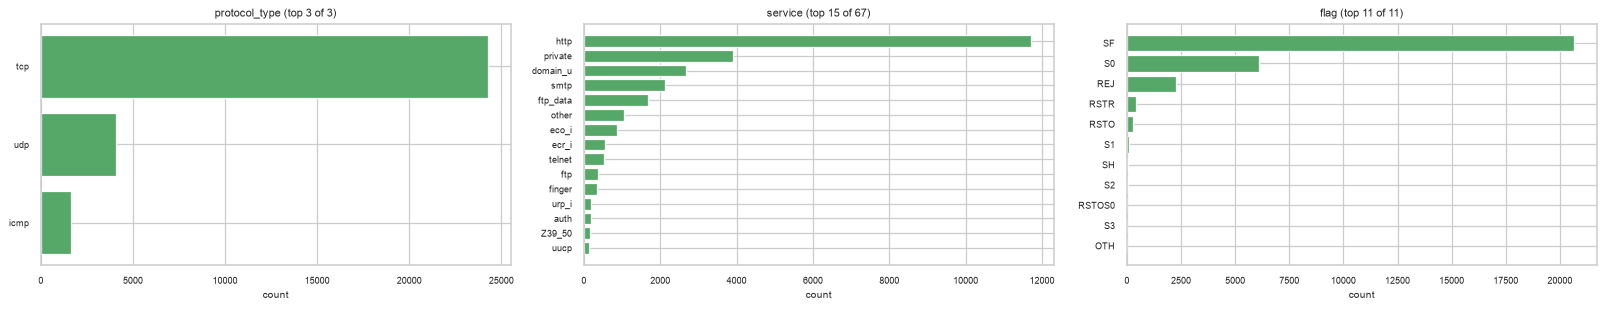

In [6]:
univariate_categorical(nslkdd, nslkdd_types["categorical_cols"], "NSL-KDD")

### 1.4 Outlier Detection

OUTLIER DETECTION — NSL-KDD


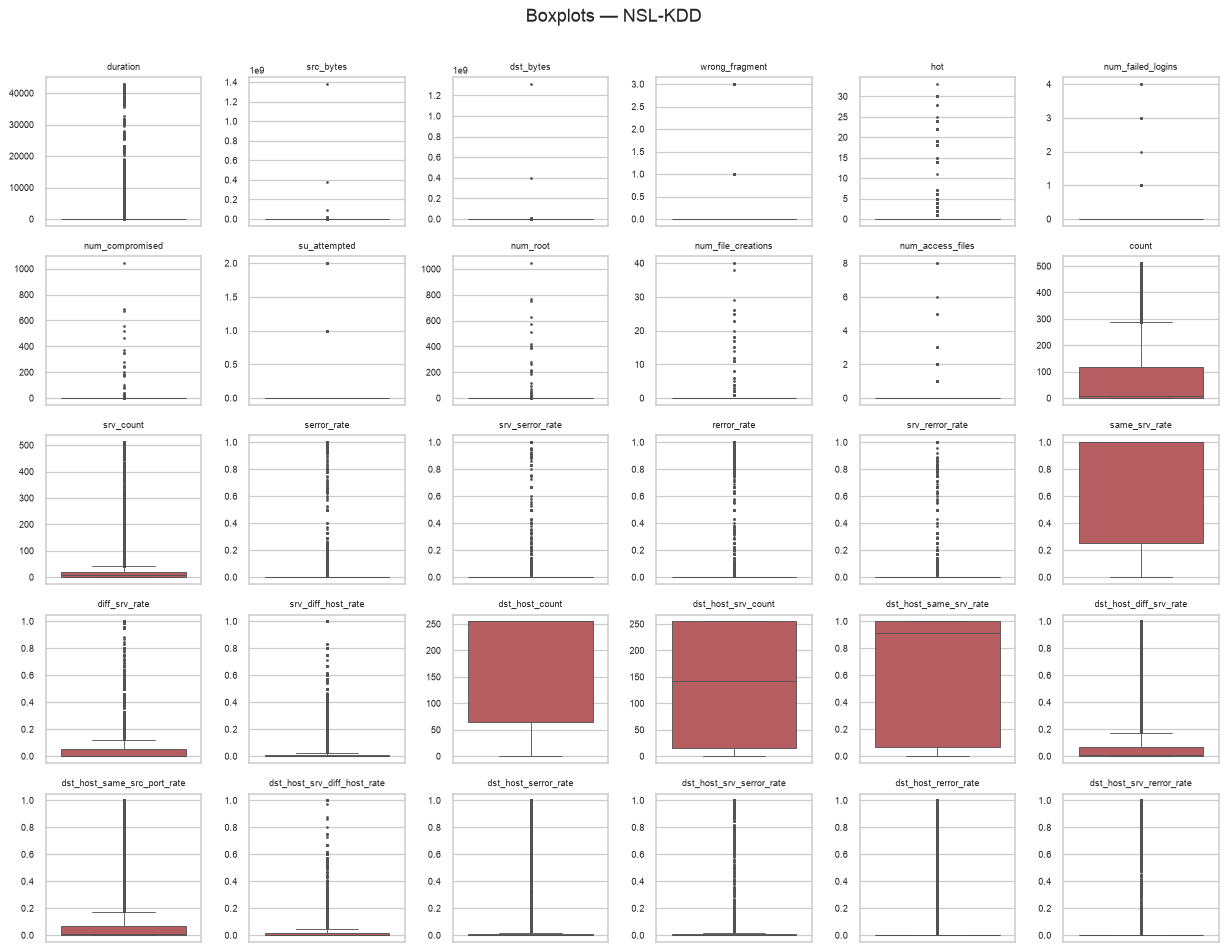

,feature,iqr_outlier_pct
26,dst_host_serror_rate,24.05
13,serror_rate,23.61
19,srv_diff_host_rate,23.09
14,srv_serror_rate,22.63
27,dst_host_srv_serror_rate,21.37
24,dst_host_same_src_port_rate,18.47
28,dst_host_rerror_rate,16.03
2,dst_bytes,14.62
29,dst_host_srv_rerror_rate,13.66
1,src_bytes,11.56



IsolationForest (contamination=0.02) flagged 400 / 20,000 normal rows (2.00%) as within-class outliers.
After also dropping exact duplicates: 19,600 rows kept (0 additional duplicate rows removed).


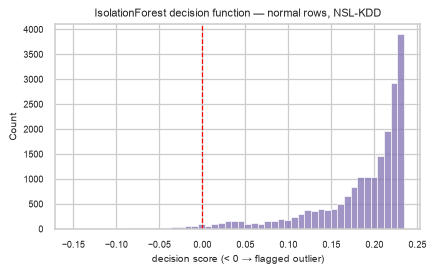

In [7]:
nslkdd_outliers = outlier_report(nslkdd, nslkdd_types["continuous_cols"], "NSL-KDD", contamination=0.02)

### 1.5 Feature Correlation

FEATURE CORRELATION — NSL-KDD


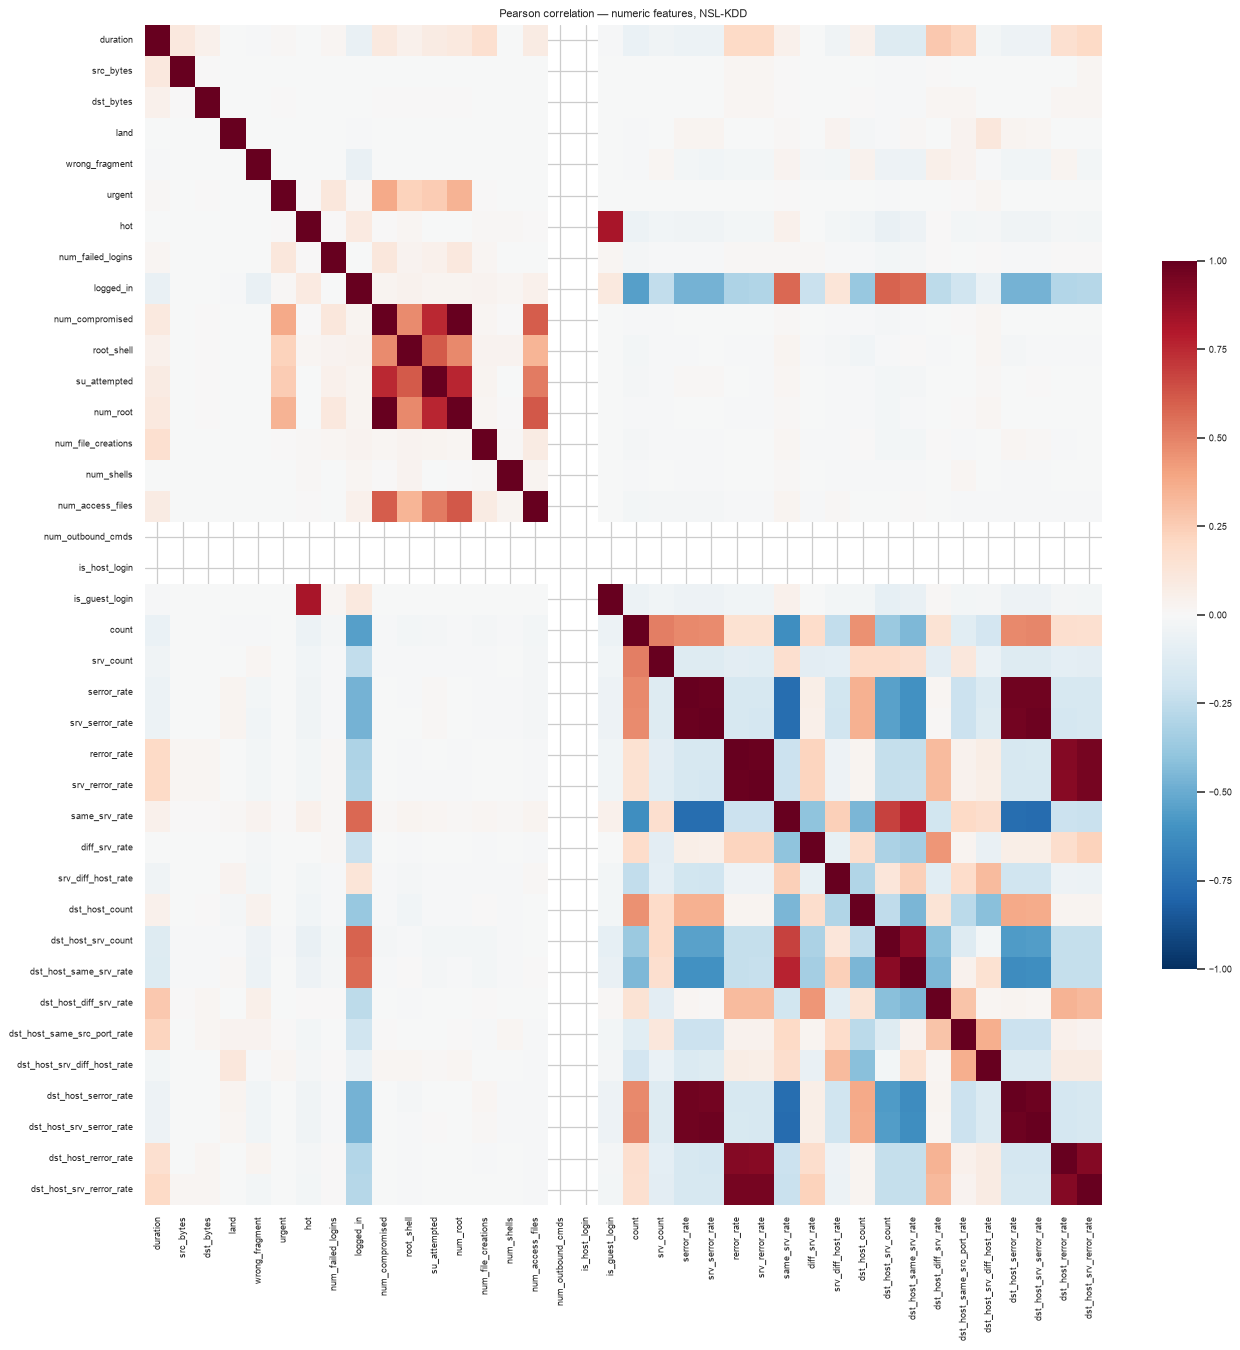


Highly correlated / redundant pairs (|r| >= 0.9): 14


,feature_1,feature_2,pearson_r
0,num_compromised,num_root,0.996
1,serror_rate,srv_serror_rate,0.992
6,rerror_rate,srv_rerror_rate,0.988
12,dst_host_serror_rate,dst_host_srv_serror_rate,0.981
5,srv_serror_rate,dst_host_srv_serror_rate,0.979
3,serror_rate,dst_host_srv_serror_rate,0.973
2,serror_rate,dst_host_serror_rate,0.970
4,srv_serror_rate,dst_host_serror_rate,0.968
10,srv_rerror_rate,dst_host_srv_rerror_rate,0.961
8,rerror_rate,dst_host_srv_rerror_rate,0.956


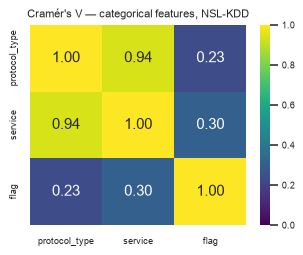

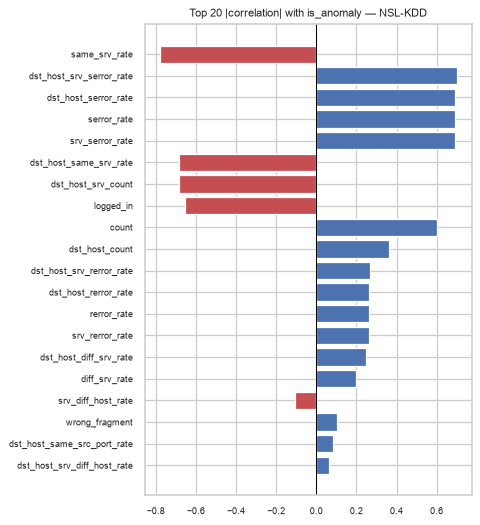

In [8]:
nslkdd_corr = correlation_report(nslkdd, nslkdd_types["numeric_cols"], nslkdd_types["categorical_cols"], "NSL-KDD")

### 1.6 Dimensionality View (additional step)
A quick PCA sanity check on how linearly separable normal vs. abnormal already are.

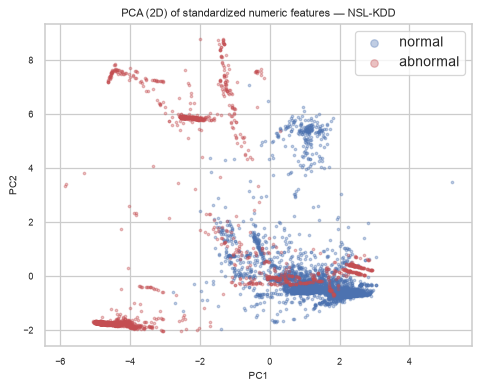

In [9]:
pca_scatter(nslkdd, nslkdd_types["numeric_cols"], "NSL-KDD")


### 1.7 Domain Constraints

Rules below were derived from the KDD Cup 1999 feature definitions **and verified empirically
against the released training data** (not assumed) — e.g. `su_attempted` is documented
loosely but actually takes 3 values `{0,1,2}` in this data, and the login/root-shell logical
rule holds with zero violations, which is exactly the kind of check that should reject
nonsensical synthetic rows later.


In [10]:

rate_cols = [c for c in nslkdd_types["numeric_cols"] if c.endswith("_rate")]
binary01_cols = ["land", "urgent", "logged_in", "root_shell", "num_shells", "is_guest_login"]
nonneg_cols = ["duration", "src_bytes", "dst_bytes", "wrong_fragment", "hot", "num_failed_logins",
               "num_compromised", "num_root", "num_file_creations", "num_access_files",
               "count", "srv_count", "dst_host_count", "dst_host_srv_count"]

nslkdd_rules = [
    {
        "name": "rate_features_in_[0,1]",
        "description": "All *_rate features are percentages and must lie in [0, 1].",
        "check": lambda d: d[rate_cols].apply(lambda s: s.between(0, 1)).all(axis=1),
        "spec": {c: {"min": 0.0, "max": 1.0} for c in rate_cols},
    },
    {
        "name": "binary_flags_in_{0,1}",
        "description": "land, urgent, logged_in, root_shell, num_shells, is_guest_login must be 0 or 1.",
        "check": lambda d: d[binary01_cols].isin([0, 1]).all(axis=1),
        "spec": {c: {"allowed": [0, 1]} for c in binary01_cols},
    },
    {
        "name": "su_attempted_in_{0,1,2}",
        "description": "Documented as a flag but observed with a 3rd state (2) in this release; "
                        "not strictly binary.",
        "check": lambda d: d["su_attempted"].isin([0, 1, 2]),
        "spec": {"su_attempted": {"allowed": [0, 1, 2]}},
    },
    {
        "name": "protocol_type_known_set",
        "description": "protocol_type must be one of {tcp, udp, icmp}.",
        "check": lambda d: d["protocol_type"].isin(["tcp", "udp", "icmp"]),
        "spec": {"protocol_type": {"allowed": sorted(nslkdd["protocol_type"].unique().tolist())}},
    },
    {
        "name": "nonneg_count_byte_duration_features",
        "description": "Byte counts, durations, and traffic counters cannot be negative.",
        "check": lambda d: (d[nonneg_cols] >= 0).all(axis=1),
        "spec": {c: {"min": 0.0} for c in nonneg_cols},
    },
    {
        "name": "root_privilege_requires_login",
        "description": "logged_in==0 => root_shell==0 and su_attempted==0 (cannot gain root "
                        "privilege without first logging in). Holds with 0 violations in the "
                        "released training data.",
        "check": lambda d: ~((d["logged_in"] == 0) & ((d["root_shell"] == 1) | (d["su_attempted"] > 0))),
        "spec": None,
    },
]

nslkdd_constraint_report, nslkdd_spec = run_constraint_rules(nslkdd, nslkdd_rules, "NSL-KDD")
nslkdd_spec["drop_columns_zero_variance"] = ["num_outbound_cmds", "is_host_login"]
save_constraints(nslkdd_spec, DATASETS["NSL-KDD"]["slug"])


DOMAIN CONSTRAINTS — NSL-KDD


,rule,description,n_violations,pct_violations
0,"rate_features_in_[0,1]",All *_rate features are percentages and must l...,0,0.0
1,"binary_flags_in_{0,1}","land, urgent, logged_in, root_shell, num_shell...",0,0.0
2,"su_attempted_in_{0,1,2}",Documented as a flag but observed with a 3rd s...,0,0.0
3,protocol_type_known_set,"protocol_type must be one of {tcp, udp, icmp}.",0,0.0
4,nonneg_count_byte_duration_features,"Byte counts, durations, and traffic counters c...",0,0.0
5,root_privilege_requires_login,logged_in==0 => root_shell==0 and su_attempted...,0,0.0


Saved post-processing constraint spec -> eda_outputs/nslkdd_constraints.json


### 1.8 Export scrubbed normal training set

In [11]:

nslkdd_scrubbed = nslkdd_outliers["scrubbed_normal"]
out_path = OUTPUT_DIR / "nslkdd_scrubbed_normal.csv"
nslkdd_scrubbed.to_csv(out_path, index=False)
print(f"Scrubbed NSL-KDD normal set: {nslkdd_scrubbed.shape} -> {out_path}")


Scrubbed NSL-KDD normal set: (19600, 42) -> eda_outputs/nslkdd_scrubbed_normal.csv



## 2. Dataset B — UNSW-NB15

IXIA PerfectStorm-generated network-flow data; one row = one network flow; 39 numeric + 3
categorical (`proto`, `service`, `state`) features; label `is_anomaly`. Note `service == "-"`
is a **documented valid category** ("not a well-known service"), not a missing value.


### 2.1 Schema Verification

In [12]:

unsw = pd.read_csv(DATASETS["UNSW-NB15"]["path"])
unsw_types = schema_report(unsw, "UNSW-NB15")


SCHEMA VERIFICATION — UNSW-NB15
Shape: 50,000 rows x 43 columns

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 43 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   dur                50000 non-null  float64
 1   spkts              50000 non-null  int64  
 2   dpkts              50000 non-null  int64  
 3   sbytes             50000 non-null  int64  
 4   dbytes             50000 non-null  int64  
 5   rate               50000 non-null  float64
 6   sttl               50000 non-null  int64  
 7   dttl               50000 non-null  int64  
 8   sload              50000 non-null  float64
 9   dload              50000 non-null  float64
 10  sloss              50000 non-null  int64  
 11  dloss              50000 non-null  int64  
 12  sinpkt             50000 non-null  float64
 13  dinpkt             50000 non-null  float64
 14  sjit               50000 non-null  float64
 15  djit            


Exact duplicate rows: 0 (0.000%)
Constant columns (zero variance): []
Near-constant columns (2 distinct non-{0,1} values): []

Label balance:
is_anomaly
normal (0)      0.7
abnormal (1)    0.3
Name: proportion, dtype: float64


,n_unique
is_anomaly,2
is_sm_ips_ports,2
is_ftp_login,4
ct_ftp_cmd,4
trans_depth,6
ct_state_ttl,6
state,8
dwin,8
ct_flw_http_mthd,8
dttl,9


### 2.2 Missingness

MISSINGNESS — UNSW-NB15
No NaN values detected in any column (curated benchmark dataset).


  Sentinel token in 'service': {'-': 30949} covering 61.90% of rows — per the data dictionary this is a valid category (e.g. 'no well-known service'), NOT missingness, so it must not be imputed.


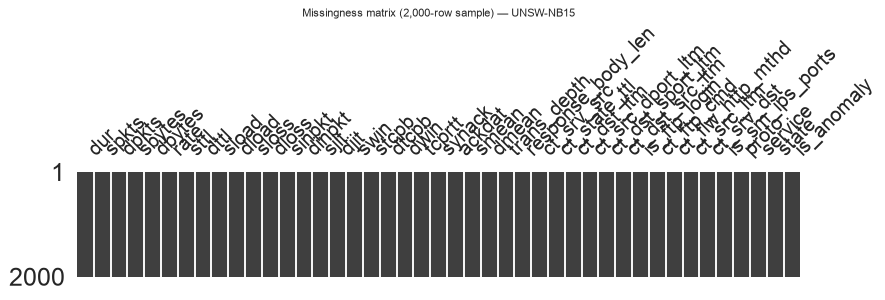

In [13]:
missingness_report(unsw, "UNSW-NB15")

### 2.3 Univariate Profiling

UNIVARIATE PROFILING — numeric — UNSW-NB15


,feature,skew,kurtosis,pct_zero,min,max,transform_suggestion
25,trans_depth,168.54,34255.21,86.0,0.0,1.720000e+02,log1p (heavy right-skew)
26,response_body_len,62.15,5465.80,90.0,0.0,6.558056e+06,log1p (heavy right-skew)
3,sbytes,42.78,2076.93,0.0,24.0,1.250037e+07,log1p (heavy right-skew)
10,sloss,41.84,2014.33,23.7,0.0,4.694000e+03,log1p (heavy right-skew)
1,spkts,35.41,1596.96,0.0,1.0,9.392000e+03,log1p (heavy right-skew)
11,dloss,34.63,2308.38,25.3,0.0,5.425000e+03,log1p (heavy right-skew)
4,dbytes,32.38,2053.51,12.5,0.0,1.449179e+07,log1p (heavy right-skew)
2,dpkts,30.60,1915.51,12.5,0.0,1.085000e+04,log1p (heavy right-skew)
15,djit,27.33,1033.64,23.8,0.0,2.893883e+05,log1p (heavy right-skew)
13,dinpkt,26.24,814.64,12.5,0.0,5.773924e+04,log1p (heavy right-skew)


31/38 continuous features are heavily right-skewed and should be log1p-transformed before fitting a generator, then inverse-transformed (expm1) on output.


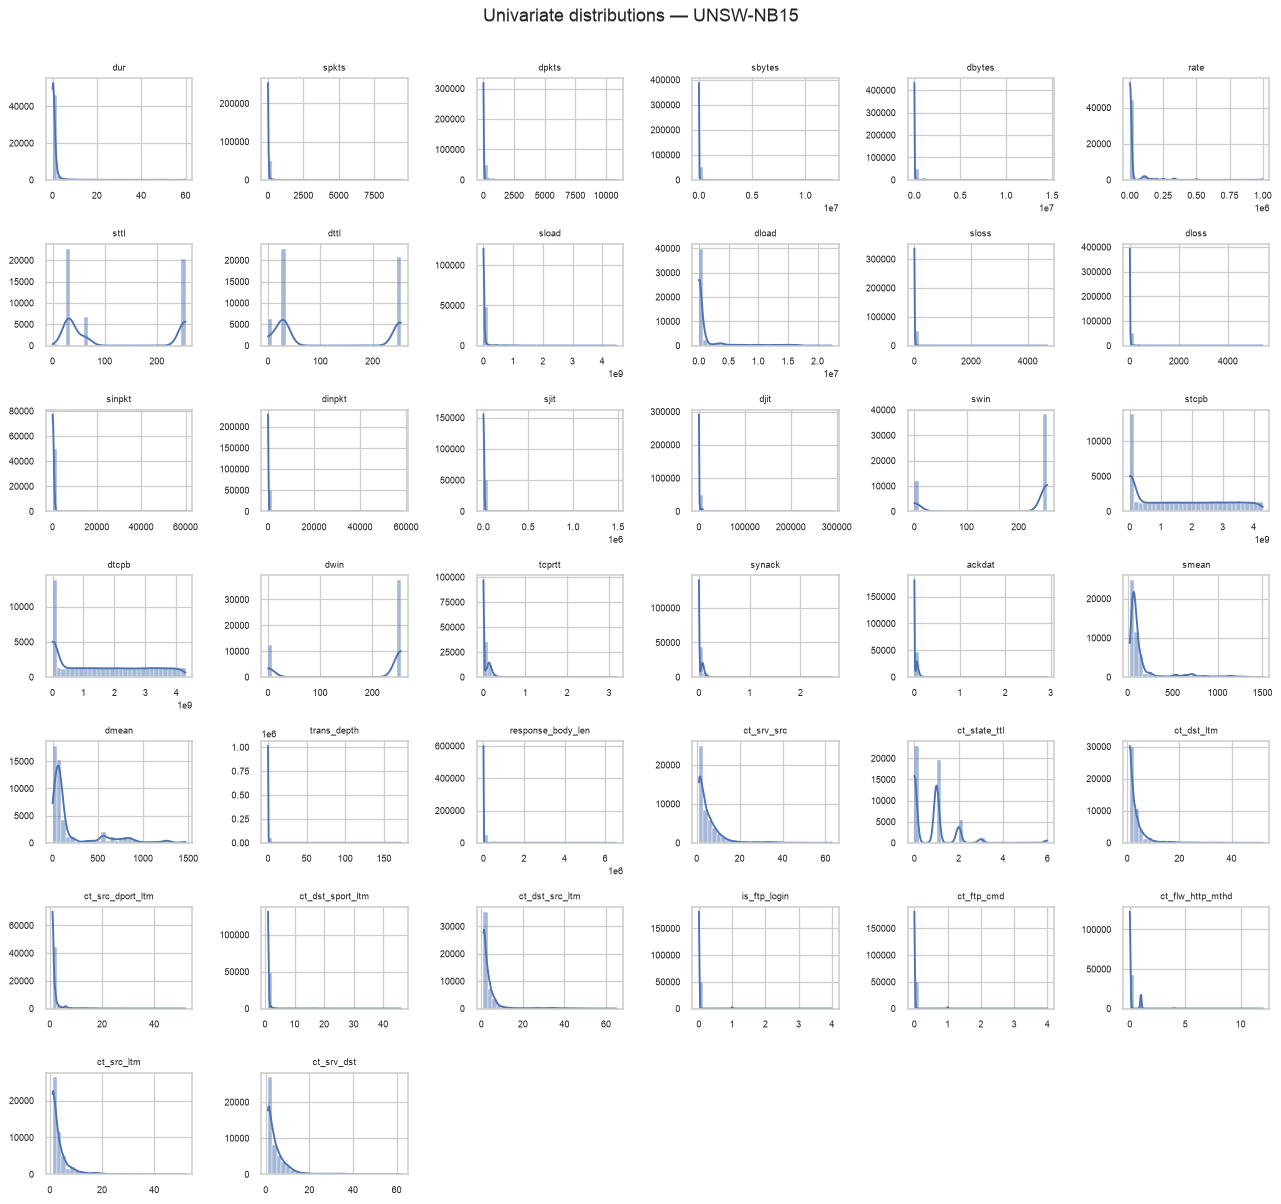

In [14]:
unsw_num_stats = univariate_numeric(unsw, unsw_types["continuous_cols"], "UNSW-NB15")

UNIVARIATE PROFILING — categorical — UNSW-NB15


,n_categories
proto,86
service,13
state,8


  'proto' is high-cardinality (86 levels); top-5 levels cover 99.7% of rows — recommend bucketing the long tail into an 'other' category before generative modelling to avoid inventing implausible rare levels.


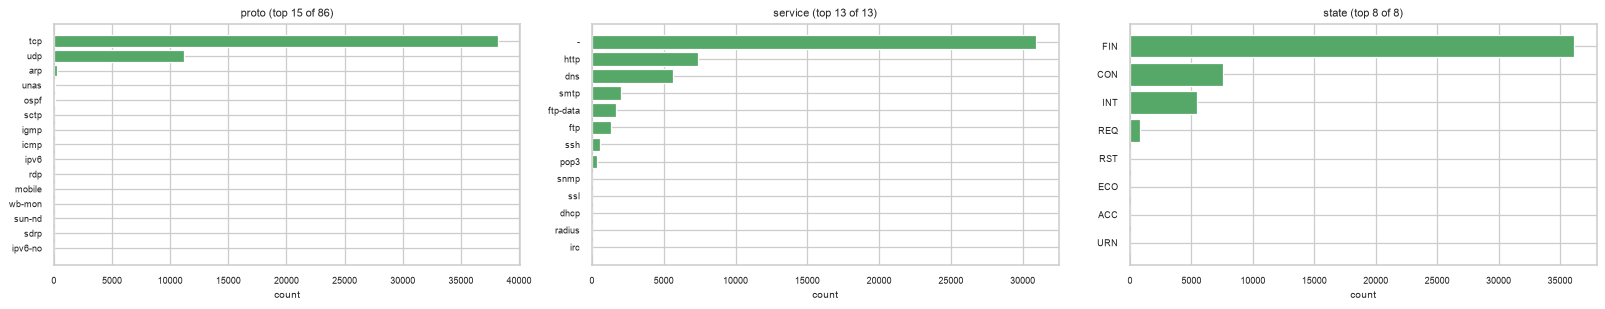

In [15]:
univariate_categorical(unsw, unsw_types["categorical_cols"], "UNSW-NB15")

### 2.4 Outlier Detection

OUTLIER DETECTION — UNSW-NB15


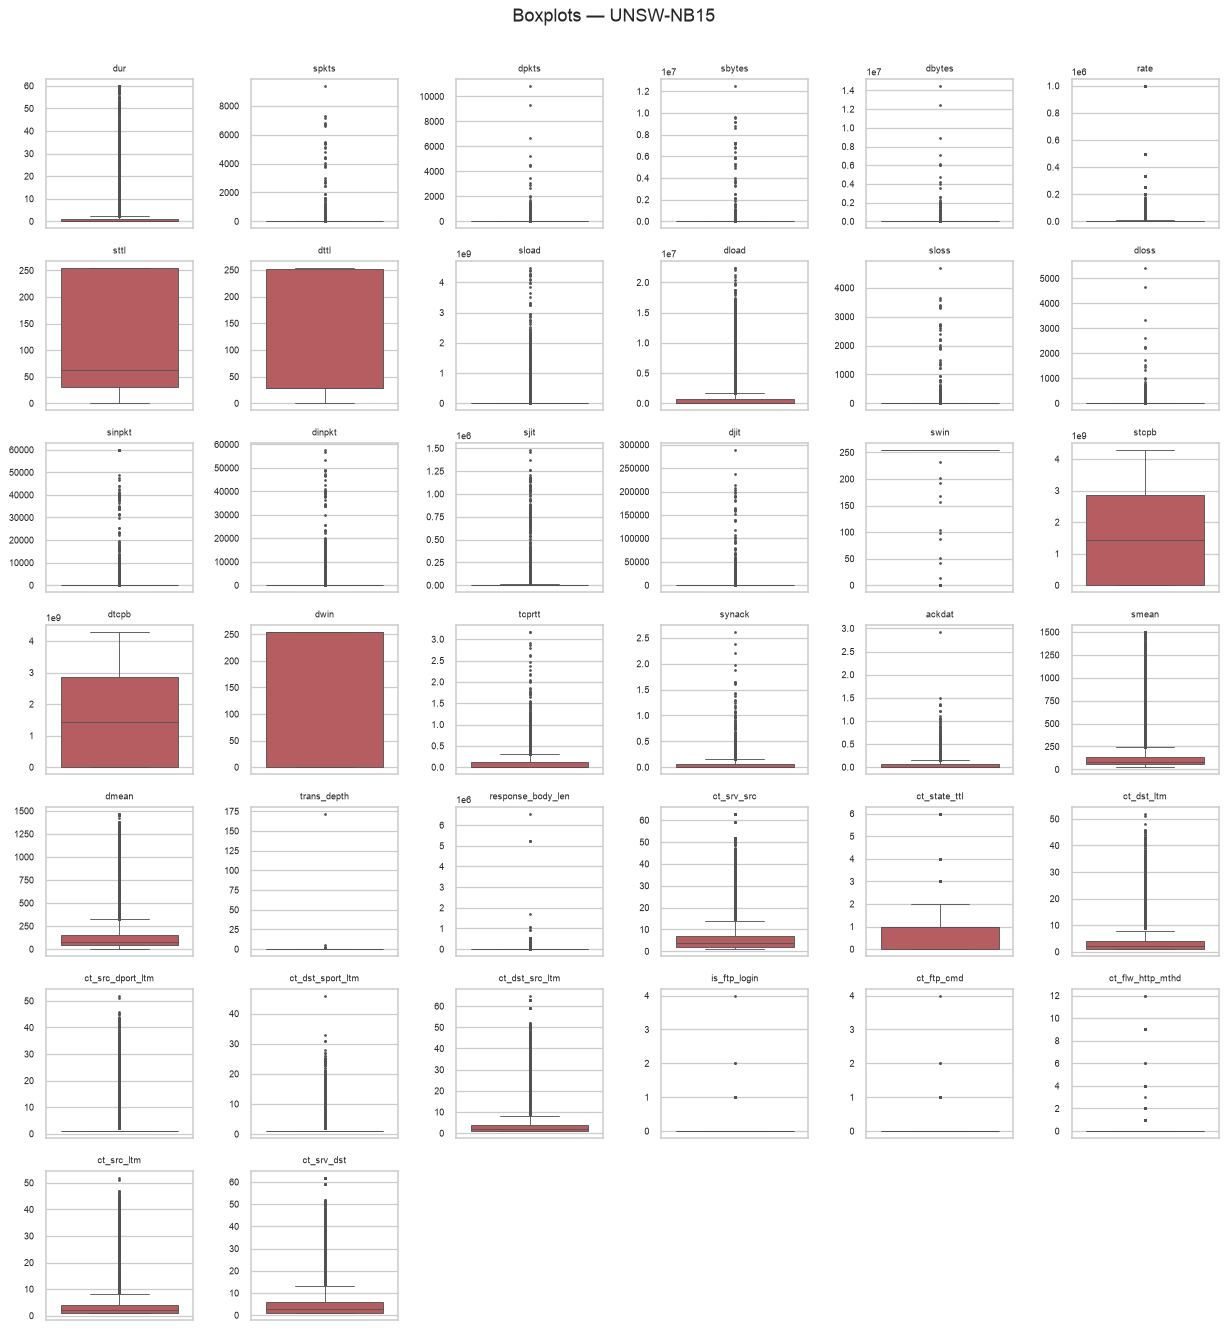

,feature,iqr_outlier_pct
30,ct_src_dport_ltm,24.66
16,swin,23.60
4,dbytes,21.29
24,dmean,20.72
1,spkts,16.79
8,sload,15.85
9,dload,15.11
35,ct_flw_http_mthd,14.03
25,trans_depth,14.03
23,smean,13.95



IsolationForest (contamination=0.02) flagged 700 / 35,000 normal rows (2.00%) as within-class outliers.
After also dropping exact duplicates: 34,300 rows kept (0 additional duplicate rows removed).


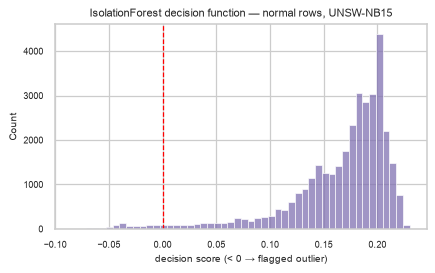

In [16]:
unsw_outliers = outlier_report(unsw, unsw_types["continuous_cols"], "UNSW-NB15", contamination=0.02)

### 2.5 Feature Correlation

FEATURE CORRELATION — UNSW-NB15


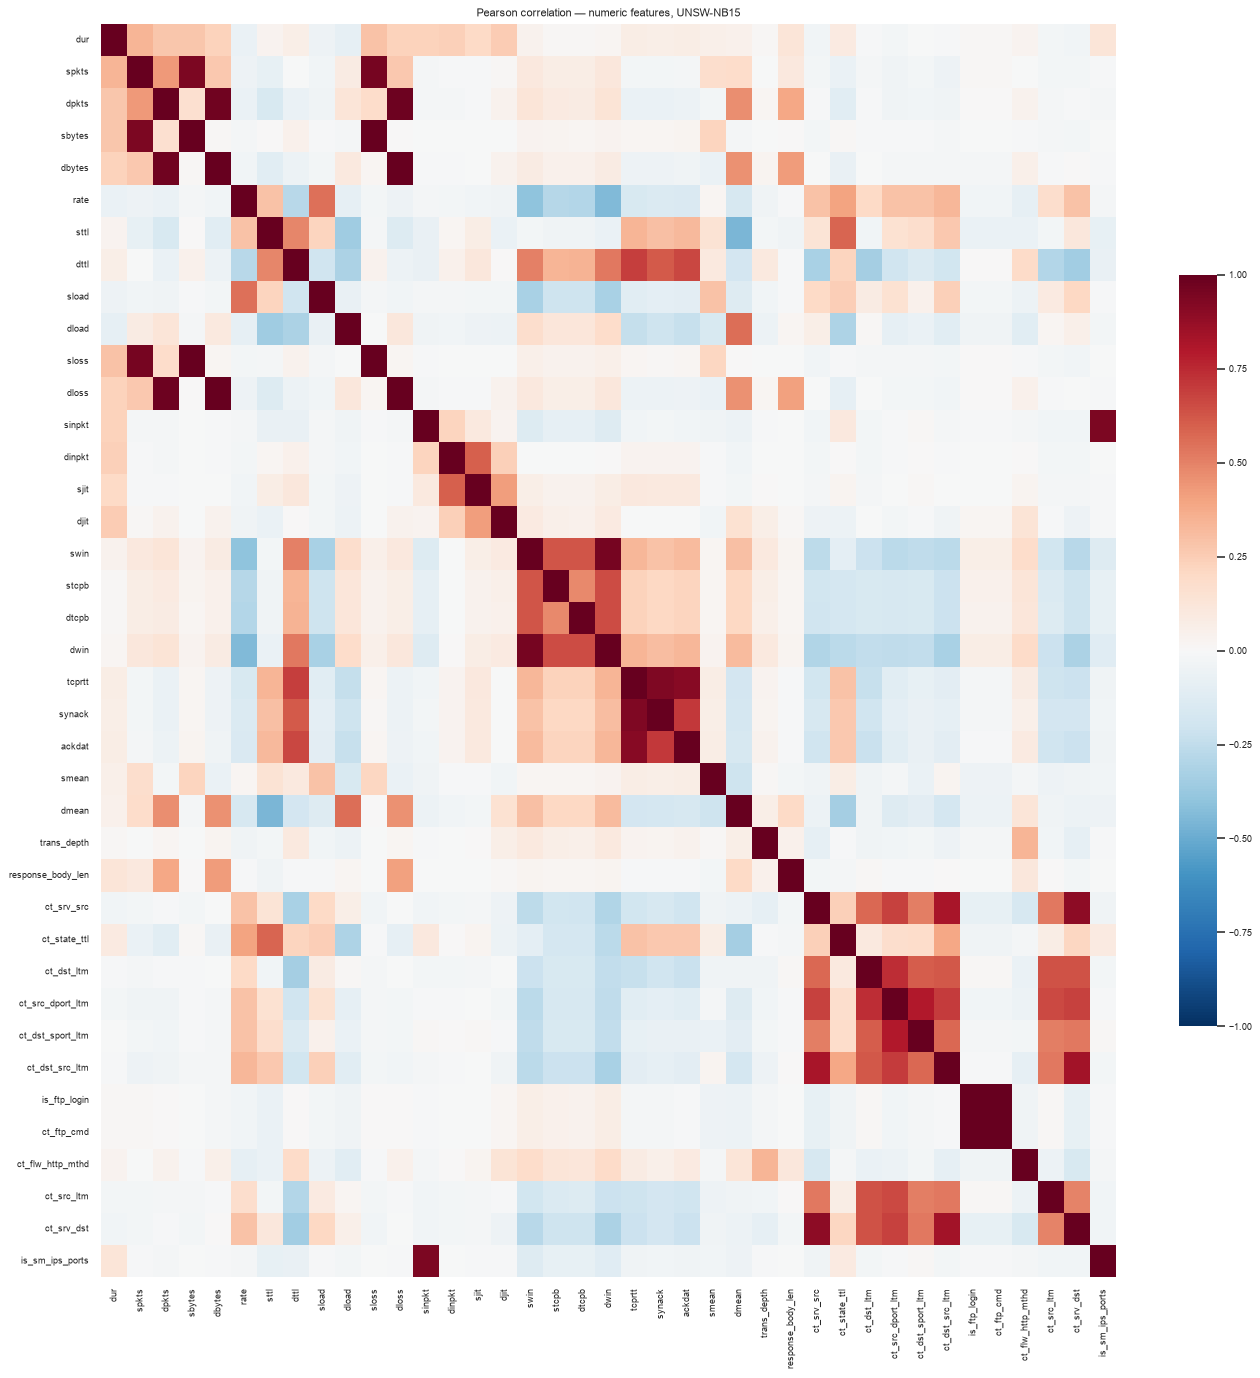


Highly correlated / redundant pairs (|r| >= 0.9): 11


,feature_1,feature_2,pearson_r
10,is_ftp_login,ct_ftp_cmd,0.999
5,dbytes,dloss,0.996
4,sbytes,sloss,0.995
3,dpkts,dloss,0.982
2,dpkts,dbytes,0.974
7,swin,dwin,0.960
1,spkts,sloss,0.955
6,sinpkt,is_sm_ips_ports,0.944
0,spkts,sbytes,0.942
8,tcprtt,synack,0.936


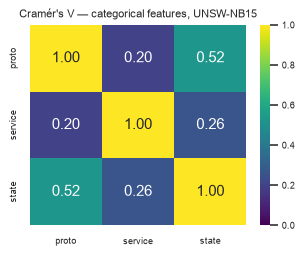

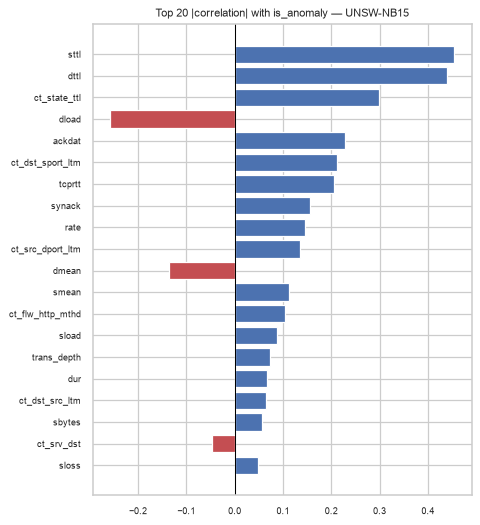

In [17]:
unsw_corr = correlation_report(unsw, unsw_types["numeric_cols"], unsw_types["categorical_cols"], "UNSW-NB15")

### 2.6 Dimensionality View (additional step)

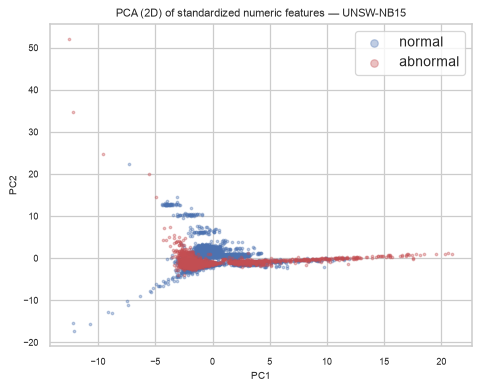

In [18]:
pca_scatter(unsw, unsw_types["numeric_cols"], "UNSW-NB15")


### 2.7 Domain Constraints

As with NSL-KDD, rules are grounded in what the data actually does, not just the data
dictionary — e.g. `is_ftp_login` is documented as binary but is observed with values 0–4
(repeated login attempts), and `tcprtt = synack + ackdat` holds to floating-point precision,
making it a strong candidate hard constraint for filtering synthetic rows.


In [19]:

unsw_nonneg_cols = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "sload", "dload",
                     "sloss", "dloss", "sinpkt", "dinpkt", "sjit", "djit", "tcprtt", "synack",
                     "ackdat", "smean", "dmean", "trans_depth", "response_body_len",
                     "ct_srv_src", "ct_state_ttl", "ct_dst_ltm", "ct_src_dport_ltm",
                     "ct_dst_sport_ltm", "ct_dst_src_ltm", "ct_ftp_cmd", "ct_flw_http_mthd",
                     "ct_src_ltm", "ct_srv_dst"]

unsw_rules = [
    {
        "name": "nonneg_traffic_features",
        "description": "Packet/byte counts, rates, timers, and connection counters cannot be negative.",
        "check": lambda d: (d[unsw_nonneg_cols] >= 0).all(axis=1),
        "spec": {c: {"min": 0.0} for c in unsw_nonneg_cols},
    },
    {
        "name": "ttl_byte_range",
        "description": "sttl / dttl are IP TTL values and must fit an 8-bit field [0, 255].",
        "check": lambda d: d["sttl"].between(0, 255) & d["dttl"].between(0, 255),
        "spec": {"sttl": {"min": 0, "max": 255}, "dttl": {"min": 0, "max": 255}},
    },
    {
        "name": "tcp_window_observed_range",
        "description": "swin / dwin are byte-scaled TCP window values observed in [0, 255] "
                        "in this release (not the full 16-bit range the protocol allows).",
        "check": lambda d: d["swin"].between(0, 255) & d["dwin"].between(0, 255),
        "spec": {"swin": {"min": 0, "max": 255}, "dwin": {"min": 0, "max": 255}},
    },
    {
        "name": "binary_flags_in_{0,1}",
        "description": "is_sm_ips_ports must be 0 or 1.",
        "check": lambda d: d["is_sm_ips_ports"].isin([0, 1]),
        "spec": {"is_sm_ips_ports": {"allowed": [0, 1]}},
    },
    {
        "name": "ftp_login_observed_range",
        "description": "is_ftp_login / ct_ftp_cmd are documented as binary-ish but observed "
                        "with small integer counts beyond {0,1} in this release.",
        "check": lambda d: d["is_ftp_login"].between(0, int(unsw["is_ftp_login"].max())),
        "spec": {"is_ftp_login": {"min": 0, "max": int(unsw["is_ftp_login"].max())},
                 "ct_ftp_cmd": {"min": 0, "max": int(unsw["ct_ftp_cmd"].max())}},
    },
    {
        "name": "nontcp_fields_zeroed",
        "description": "TCP-only fields (swin, dwin, stcpb, dtcpb) must be 0 whenever "
                        "proto != 'tcp'. Holds with 0 violations in the released training data.",
        "check": lambda d: (d["proto"] == "tcp") | ((d["swin"] == 0) & (d["dwin"] == 0) & (d["stcpb"] == 0) & (d["dtcpb"] == 0)),
        "spec": None,
    },
    {
        "name": "tcprtt_consistency",
        "description": "tcprtt must equal synack + ackdat (TCP handshake timing decomposition). "
                        "Holds to floating-point precision in the released training data — "
                        "recompute rather than independently sample these 3 columns.",
        "check": lambda d: (d["tcprtt"] - (d["synack"] + d["ackdat"])).abs() < 1e-6,
        "spec": None,
    },
    {
        "name": "state_known_set",
        "description": "state must be one of the connection-state codes observed in training.",
        "check": lambda d: d["state"].isin(sorted(unsw["state"].unique().tolist())),
        "spec": {"state": {"allowed": sorted(unsw["state"].unique().tolist())}},
    },
]

unsw_constraint_report, unsw_spec = run_constraint_rules(unsw, unsw_rules, "UNSW-NB15")
save_constraints(unsw_spec, DATASETS["UNSW-NB15"]["slug"])


DOMAIN CONSTRAINTS — UNSW-NB15


,rule,description,n_violations,pct_violations
0,nonneg_traffic_features,"Packet/byte counts, rates, timers, and connect...",0,0.0
1,ttl_byte_range,sttl / dttl are IP TTL values and must fit an ...,0,0.0
2,tcp_window_observed_range,swin / dwin are byte-scaled TCP window values ...,0,0.0
3,"binary_flags_in_{0,1}",is_sm_ips_ports must be 0 or 1.,0,0.0
4,ftp_login_observed_range,is_ftp_login / ct_ftp_cmd are documented as bi...,0,0.0
5,nontcp_fields_zeroed,"TCP-only fields (swin, dwin, stcpb, dtcpb) mus...",0,0.0
6,tcprtt_consistency,tcprtt must equal synack + ackdat (TCP handsha...,0,0.0
7,state_known_set,state must be one of the connection-state code...,0,0.0


Saved post-processing constraint spec -> eda_outputs/unsw_constraints.json


### 2.8 Export scrubbed normal training set

In [20]:

unsw_scrubbed = unsw_outliers["scrubbed_normal"]
out_path = OUTPUT_DIR / "unsw_scrubbed_normal.csv"
unsw_scrubbed.to_csv(out_path, index=False)
print(f"Scrubbed UNSW-NB15 normal set: {unsw_scrubbed.shape} -> {out_path}")


Scrubbed UNSW-NB15 normal set: (34300, 43) -> eda_outputs/unsw_scrubbed_normal.csv


## 3. Cross-Dataset Comparison

In [21]:

summary_rows = []
for name, df, types, outl in [
    ("NSL-KDD", nslkdd, nslkdd_types, nslkdd_outliers),
    ("UNSW-NB15", unsw, unsw_types, unsw_outliers),
]:
    summary_rows.append({
        "dataset": name,
        "n_rows": len(df),
        "n_features": len(types["feature_cols"]),
        "n_continuous": len(types["continuous_cols"]),
        "n_binary": len(types["binary_cols"]),
        "n_categorical": len(types["categorical_cols"]),
        "pct_abnormal": round(df[LABEL_COL].mean() * 100, 2),
        "n_duplicate_rows": int(df.duplicated().sum()),
        "n_heavy_skew_features": int((abs(df[types["continuous_cols"]].skew()) > 2).sum()),
        "n_iso_outliers_in_normal": int(outl["iqr_table"].shape[0] and (df[LABEL_COL] == 0).sum() - len(outl["scrubbed_normal"])),
    })
summary_df = pd.DataFrame(summary_rows).set_index("dataset")
display(summary_df)
summary_df.to_csv(OUTPUT_DIR / "cross_dataset_summary.csv")


,n_rows,n_features,n_continuous,n_binary,n_categorical,pct_abnormal,n_duplicate_rows,n_heavy_skew_features,n_iso_outliers_in_normal
dataset,,,,,,,,,
NSL-KDD,30000,41,30,8,3,33.33,1,21,400
UNSW-NB15,50000,42,38,1,3,30.00,0,31,700



## 4. Key Findings → Augmentation Design Recommendations

| Finding | Evidence | Design implication |
|---|---|---|
| Mixed feature types (continuous / binary / small-integer / categorical) | Section 1.1 / 2.1 type split | The generator must model each type appropriately (e.g. discrete heads for binary/categorical, continuous heads for the rest) rather than sampling everything as continuous and rounding — rounding a categorical code or a rate produces invalid values. |
| Several features are heavily right-skewed (`src_bytes`, `dst_bytes`, byte/packet counters, `rate`) | Section 1.3 / 2.3 skew table | Fit generative models on `log1p`-transformed values and invert with `expm1` on generation, rather than modelling raw heavy-tailed distributions directly. |
| A small fraction of *normal*-labelled rows are themselves IsolationForest outliers | Section 1.4 / 2.4 | Train the generator on the **scrubbed** normal set (exported to `eda_outputs/`), not the raw normal subset — otherwise the generator learns to reproduce likely-mislabeled or noisy edge cases. |
| Numeric features are strongly inter-correlated (traffic-rate and `dst_host_*` families in NSL-KDD; `tcprtt = synack + ackdat` and TCP-field families in UNSW-NB15) | Section 1.5 / 2.5, and the exact-equality constraint rules | A generator that samples columns independently will break these dependencies and produce detectably-fake rows. Prefer a **joint** generative approach (e.g. a copula, VAE, or diffusion model over the full feature vector) and/or re-derive dependent columns deterministically after generation (e.g. recompute `tcprtt`). |
| `service`/`proto` are high-cardinality (67 / 86 levels) with long tails | Section 1.3 / 2.3 categorical audit | Bucket rare categories into `other` before modelling; sample from the empirical (bucketed) category distribution rather than letting a generator invent implausible rare-category combinations. |
| Hard logical/range constraints hold with (near-)zero violations in real data (`rate` ∈ [0,1], TTL ∈ [0,255], no root shell without login, TCP fields zero for non-TCP, `tcprtt` identity) | Sections 1.6 / 2.6 constraint tables, saved to `*_constraints.json` | Apply these as a **deterministic post-processing filter**: clip/reject any generated row that violates them before submission. This is cheap insurance against AUPRC-damaging, obviously-fake rows regardless of which generative method is used. |
| Exact duplicate rows exist (1 in NSL-KDD; a nontrivial IQR-outlier tail in both) | Sections 1.1/2.1, 1.4/2.4 | Deduplicate before training the generator to avoid over-weighting repeated connections. |
| Constant columns carry no signal (`num_outbound_cmds`, `is_host_login` in NSL-KDD) | Section 1.1 | Drop before modelling and exclude from any fidelity/utility diagnostics — they cannot help or hurt detector training. |
| PCA shows partial but incomplete linear separability between normal/abnormal, and hidden validation/test sets contain **unseen** attack types | Sections 1.6/2.6; problem PDF §2 | Optimize the generator for **coverage/diversity of the normal manifold**, not tight reproduction of the training normal centroid — a detector's ability to flag *novel* anomaly types depends on how well it has learned the normal boundary, not on memorized normal points. |
| Same pipeline must serve both datasets | Project brief | The function library in Section 0 (schema/outlier/correlation/constraint logic) is dataset-agnostic; only the per-dataset **rule specs** (Sections 1.7 / 2.7) and skew tables differ — this is the template the augmentation pipeline should follow (shared code, per-dataset config).|

**Artifacts produced by this notebook** (all under `eda_outputs/`):
- `nslkdd_scrubbed_normal.csv`, `unsw_scrubbed_normal.csv` — deduplicated, IsolationForest-scrubbed normal-only training data.
- `nslkdd_constraints.json`, `unsw_constraints.json` — machine-readable range/set/drop-column rules for post-processing rejection of synthetic rows.
- `cross_dataset_summary.csv` — the comparison table above, in tabular form.
